In [ ]:
import os
import random
import time
import copy
import numpy as np
import pandas as pd
import tracemalloc
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torchvision.ops import sigmoid_focal_loss
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import confusion_matrix, accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import QuantileTransformer
from sklearn.compose import ColumnTransformer
from sklearn.metrics import f1_score, precision_score, recall_score, confusion_matrix, classification_report, roc_curve, roc_auc_score
from tqdm import tqdm
import glob
import joblib

# 1. Configuration de la Reproductibilité
SEED = 42

def set_seed(seed=42):
    """Fixe les graines aléatoires pour garantir la reproductibilité totale des résultats."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    # Pour des convolutions déterministes (peut ralentir légèrement mais essentiel pour la science)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    print(f"[INFO] Global Seed set to {seed}")

# 2. Gestion de l'environnement et des dossiers
def setup_env():
    """Crée l'arborescence nécessaire si elle n'existe pas."""
    directories = ['datasets', 'models']
    for d in directories:
        os.makedirs(d, exist_ok=True)
        print(f"[INFO] Dossier vérifié/créé : {d}/")
    
    # Vérification du dossier Input (Juste un warning si absent, car c'est l'utilisateur qui fournit les données)
    if not os.path.exists('CIC-IDS-2017/'):
        print("[WARNING] Le dossier input 'CIC-IDS-2017/' est introuvable. Assurez-vous d'y placer vos CSV.")
    else:
        print("[INFO] Dossier input 'CIC-IDS-2017/' détecté.")

# 3. Détection Hardware
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"[INFO] Unité de calcul active : {DEVICE}")
if DEVICE.type == 'cuda':
    print(f"[INFO] GPU : {torch.cuda.get_device_name(0)}")

# Exécution du Setup
set_seed(SEED)
setup_env()

# Configuration Pandas pour meilleure lisibilité
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)

[INFO] Unité de calcul active : cuda
[INFO] GPU : NVIDIA GeForce RTX 5070
[INFO] Global Seed set to 42
[INFO] Dossier vérifié/créé : datasets/
[INFO] Dossier vérifié/créé : models/
[INFO] Dossier input 'CIC-IDS-2017/' détecté.


# Assignment: Real-Time Intrusion Detection with Scapy + PyTorch

## Task 1: Dataset Exploration and Feature Understanding


In [ ]:
# FEATURES BRUTES
RAW_COLUMNS = [
    'Destination Port', 'Flow Duration', 'Total Fwd Packets', 'Total Backward Packets', 
    'Total Length of Fwd Packets', 'Total Length of Bwd Packets', 'Fwd Packet Length Max', 
    'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std', 
    'Bwd Packet Length Max', 'Bwd Packet Length Min', 'Bwd Packet Length Mean', 
    'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 
    'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Total', 'Fwd IAT Mean', 
    'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 
    'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Bwd PSH Flags', 
    'Fwd URG Flags', 'Bwd URG Flags', 'Fwd Header Length', 'Bwd Header Length', 
    'Fwd Packets/s', 'Bwd Packets/s', 'Min Packet Length', 'Max Packet Length', 
    'Packet Length Mean', 'Packet Length Std', 'Packet Length Variance', 'FIN Flag Count', 
    'SYN Flag Count', 'RST Flag Count', 'PSH Flag Count', 'ACK Flag Count', 'URG Flag Count', 
    'CWE Flag Count', 'ECE Flag Count', 'Down/Up Ratio', 'Average Packet Size', 
    'Avg Fwd Segment Size', 'Avg Bwd Segment Size', 'Fwd Header Length.1', 
    'Fwd Avg Bytes/Bulk', 'Fwd Avg Packets/Bulk', 'Fwd Avg Bulk Rate', 'Bwd Avg Bytes/Bulk', 
    'Bwd Avg Packets/Bulk', 'Bwd Avg Bulk Rate', 'Subflow Fwd Packets', 'Subflow Fwd Bytes', 
    'Subflow Bwd Packets', 'Subflow Bwd Bytes', 'Init_Win_bytes_forward', 
    'Init_Win_bytes_backward', 'act_data_pkt_fwd', 'min_seg_size_forward', 'Active Mean', 
    'Active Std', 'Active Max', 'Active Min', 'Idle Mean', 'Idle Std', 'Idle Max', 
    'Idle Min', 'Label'
]

# 1. FEATURES LINUX
features_linux = [
    'Flow Duration', 'Total Fwd Packets', 'Total Backward Packets', 'Total Length of Fwd Packets',
    'Total Length of Bwd Packets', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean',
    'Fwd Packet Length Std', 'Bwd Packet Length Max', 'Bwd Packet Length Min', 'Bwd Packet Length Mean',
    'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std',
    'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max',
    'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min',
    'Fwd PSH Flags', 'Fwd Header Length', 'Bwd Header Length', 'Fwd Packets/s', 'Bwd Packets/s',
    'Min Packet Length', 'Max Packet Length', 'Packet Length Mean', 'Packet Length Std',  'Packet Length Variance', 
    'FIN Flag Count', 'SYN Flag Count', 'RST Flag Count', 'PSH Flag Count', 'ACK Flag Count', 'URG Flag Count', 
    'ECE Flag Count', 'Down/Up Ratio', 'Average Packet Size', 'Init_Win_bytes_forward', 'Init_Win_bytes_backward', 
    'act_data_pkt_fwd', 'min_seg_size_forward'
]

# 2. FEATURES RASPBERRY PI
features_pi = [
    'Flow Duration', 'Total Fwd Packets', 'Total Backward Packets', 'Total Length of Fwd Packets',
    'Total Length of Bwd Packets', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Bwd Packet Length Max',
    'Bwd Packet Length Min', 'Fwd Header Length', 'Bwd Header Length', 'Min Packet Length', 'Max Packet Length', 
    'FIN Flag Count', 'SYN Flag Count', 'PSH Flag Count', 'ACK Flag Count', 'Down/Up Ratio', 'Average Packet Size',
    'Init_Win_bytes_forward', 'Init_Win_bytes_backward', 'act_data_pkt_fwd', 'min_seg_size_forward'
]

print(f"[INFO] Features totales brutes : {len(RAW_COLUMNS)}")
print(f"[INFO] Features Linux Finales : {len(features_linux)}")
print(f"[INFO] Features Pi Finales    : {len(features_pi)}")

[INFO] Features totales brutes : 79
[INFO] Features Linux Finales : 52
[INFO] Features Pi Finales    : 23


### Task 1.2: features details


In [ ]:
# Comprehensive Feature Definitions
features_metadata = {
    'Destination Port': {'type': 'int', 'desc': 'Destination port number', 'level': 'Packet', 'relevance': 'Identifies compromised service.'},
    'Flow Duration': {'type': 'int', 'desc': 'Duration of the flow in microseconds', 'level': 'Flow', 'relevance': 'DDoS/Bruteforce result in short/long durations.'},
    'Total Fwd Packets': {'type': 'int', 'desc': 'Total packets in forward direction', 'level': 'Flow', 'relevance': 'Volume metric.'},
    'Total Backward Packets': {'type': 'int', 'desc': 'Total packets in backward direction', 'level': 'Flow', 'relevance': 'Volume metric.'},
    'Total Length of Fwd Packets': {'type': 'int', 'desc': 'Total size of packet payload in forward direction', 'level': 'Flow', 'relevance': 'Data exfiltration volume.'},
    'Total Length of Bwd Packets': {'type': 'int', 'desc': 'Total size of packet payload in backward direction', 'level': 'Flow', 'relevance': 'Download volume.'},
    'Fwd Packet Length Max': {'type': 'int', 'desc': 'Maximum size of packet in forward direction', 'level': 'Flow', 'relevance': 'MTU anomalies.'},
    'Fwd Packet Length Min': {'type': 'int', 'desc': 'Minimum size of packet in forward direction', 'level': 'Flow', 'relevance': 'Control packets.'},
    'Fwd Packet Length Mean': {'type': 'float', 'desc': 'Average size of packet in forward direction', 'level': 'Flow', 'relevance': 'Profile of application protocol.'},
    'Fwd Packet Length Std': {'type': 'float', 'desc': 'Standard deviation size of packet in forward direction', 'level': 'Flow', 'relevance': 'Variability of payload.'},
    'Bwd Packet Length Max': {'type': 'int', 'desc': 'Maximum size of packet in backward direction', 'level': 'Flow', 'relevance': ''},
    'Bwd Packet Length Min': {'type': 'int', 'desc': 'Minimum size of packet in backward direction', 'level': 'Flow', 'relevance': ''},
    'Bwd Packet Length Mean': {'type': 'float', 'desc': 'Mean size of packet in backward direction', 'level': 'Flow', 'relevance': ''},
    'Bwd Packet Length Std': {'type': 'float', 'desc': 'Standard deviation size of packet in backward direction', 'level': 'Flow', 'relevance': ''},
    'Flow Bytes/s': {'type': 'float', 'desc': 'Flow throughput in bytes per second', 'level': 'Flow', 'relevance': 'Bandwidth usage.'},
    'Flow Packets/s': {'type': 'float', 'desc': 'Flow throughput in packets per second', 'level': 'Flow', 'relevance': 'High PPS indicates DDoS.'},
    'Flow IAT Mean': {'type': 'float', 'desc': 'Mean time between two packets in the flow', 'level': 'Flow', 'relevance': 'Automated traffic has regular IAT.'},
    'Flow IAT Std': {'type': 'float', 'desc': 'Standard deviation of time between two packets', 'level': 'Flow', 'relevance': 'Jitter.'},
    'Flow IAT Max': {'type': 'int', 'desc': 'Maximum time between two packets', 'level': 'Flow', 'relevance': 'Idle periods.'},
    'Flow IAT Min': {'type': 'int', 'desc': 'Minimum time between two packets', 'level': 'Flow', 'relevance': 'Bursts.'},
    'Fwd IAT Total': {'type': 'int', 'desc': 'Total time between two forward packets', 'level': 'Flow', 'relevance': ''},
    'Fwd IAT Mean': {'type': 'float', 'desc': 'Mean time between two forward packets', 'level': 'Flow', 'relevance': ''},
    'Fwd IAT Std': {'type': 'float', 'desc': 'Standard deviation of time between two forward packets', 'level': 'Flow', 'relevance': ''},
    'Fwd IAT Max': {'type': 'int', 'desc': 'Maximum time between two forward packets', 'level': 'Flow', 'relevance': ''},
    'Fwd IAT Min': {'type': 'int', 'desc': 'Minimum time between two forward packets', 'level': 'Flow', 'relevance': ''},
    'Bwd IAT Total': {'type': 'int', 'desc': 'Total time between two backward packets', 'level': 'Flow', 'relevance': ''},
    'Bwd IAT Mean': {'type': 'float', 'desc': 'Mean time between two backward packets', 'level': 'Flow', 'relevance': ''},
    'Bwd IAT Std': {'type': 'float', 'desc': 'Standard deviation of time between two backward packets', 'level': 'Flow', 'relevance': ''},
    'Bwd IAT Max': {'type': 'int', 'desc': 'Maximum time between two backward packets', 'level': 'Flow', 'relevance': ''},
    'Bwd IAT Min': {'type': 'int', 'desc': 'Minimum time between two backward packets', 'level': 'Flow', 'relevance': ''},
    'Fwd PSH Flags': {'type': 'int', 'desc': 'Number of times the PSH flag was set in forward direction', 'level': 'Flow/Packet', 'relevance': 'Data push urgency.'},
    'Bwd PSH Flags': {'type': 'int', 'desc': 'Number of times the PSH flag was set in backward direction', 'level': 'Flow/Packet', 'relevance': ''},
    'Fwd URG Flags': {'type': 'int', 'desc': 'Number of times the URG flag was set in forward direction', 'level': 'Flow/Packet', 'relevance': ''},
    'Bwd URG Flags': {'type': 'int', 'desc': 'Number of times the URG flag was set in backward direction', 'level': 'Flow/Packet', 'relevance': ''},
    'Fwd Header Length': {'type': 'int', 'desc': 'Total bytes used for headers in forward direction', 'level': 'Flow', 'relevance': 'Tunneling overhead.'},
    'Bwd Header Length': {'type': 'int', 'desc': 'Total bytes used for headers in backward direction', 'level': 'Flow', 'relevance': ''},
    'Fwd Packets/s': {'type': 'float', 'desc': 'Number of forward packets per second', 'level': 'Flow', 'relevance': ''},
    'Bwd Packets/s': {'type': 'float', 'desc': 'Number of backward packets per second', 'level': 'Flow', 'relevance': ''},
    'Min Packet Length': {'type': 'int', 'desc': 'Minimum length of a packet', 'level': 'Flow', 'relevance': ''},
    'Max Packet Length': {'type': 'int', 'desc': 'Maximum length of a packet', 'level': 'Flow', 'relevance': ''},
    'Packet Length Mean': {'type': 'float', 'desc': 'Mean length of a packet', 'level': 'Flow', 'relevance': ''},
    'Packet Length Std': {'type': 'float', 'desc': 'Standard deviation of length of a packet', 'level': 'Flow', 'relevance': ''},
    'Packet Length Variance': {'type': 'float', 'desc': 'Variance of length of a packet', 'level': 'Flow', 'relevance': ''},
    'FIN Flag Count': {'type': 'int', 'desc': 'Number of packets with FIN', 'level': 'Flow', 'relevance': 'Connection termination.'},
    'SYN Flag Count': {'type': 'int', 'desc': 'Number of packets with SYN', 'level': 'Flow', 'relevance': 'Connection establishment.'},
    'RST Flag Count': {'type': 'int', 'desc': 'Number of packets with RST', 'level': 'Flow', 'relevance': 'Connection reset.'},
    'PSH Flag Count': {'type': 'int', 'desc': 'Number of packets with PSH', 'level': 'Flow', 'relevance': ''},
    'ACK Flag Count': {'type': 'int', 'desc': 'Number of packets with ACK', 'level': 'Flow', 'relevance': ''},
    'URG Flag Count': {'type': 'int', 'desc': 'Number of packets with URG', 'level': 'Flow', 'relevance': ''},
    'CWE Flag Count': {'type': 'int', 'desc': 'Number of packets with CWE', 'level': 'Flow', 'relevance': 'Congestion Window ECN.'},
    'ECE Flag Count': {'type': 'int', 'desc': 'Number of packets with ECE', 'level': 'Flow', 'relevance': 'ECN-Echo.'},
    'Down/Up Ratio': {'type': 'float', 'desc': 'Download and upload ratio', 'level': 'Flow', 'relevance': 'Traffic directionality.'},
    'Average Packet Size': {'type': 'float', 'desc': 'Average size of packet', 'level': 'Flow', 'relevance': ''},
    'Avg Fwd Segment Size': {'type': 'float', 'desc': 'Average size observed in the forward direction', 'level': 'Flow', 'relevance': ''},
    'Avg Bwd Segment Size': {'type': 'float', 'desc': 'Average size observed in the backward direction', 'level': 'Flow', 'relevance': ''},
    'Fwd Header Length.1': {'type': 'int', 'desc': 'Duplicate column (Header Length)', 'level': 'Flow', 'relevance': ''},
    'Fwd Avg Bytes/Bulk': {'type': 'int', 'desc': 'Average bytes/bulk in forward', 'level': 'Flow', 'relevance': ''},
    'Fwd Avg Packets/Bulk': {'type': 'int', 'desc': 'Average packets/bulk in forward', 'level': 'Flow', 'relevance': ''},
    'Fwd Avg Bulk Rate': {'type': 'int', 'desc': 'Average bulk rate in forward', 'level': 'Flow', 'relevance': ''},
    'Bwd Avg Bytes/Bulk': {'type': 'int', 'desc': 'Average bytes/bulk in backward', 'level': 'Flow', 'relevance': ''},
    'Bwd Avg Packets/Bulk': {'type': 'int', 'desc': 'Average packets/bulk in backward', 'level': 'Flow', 'relevance': ''},
    'Bwd Avg Bulk Rate': {'type': 'int', 'desc': 'Average bulk rate in backward', 'level': 'Flow', 'relevance': ''},
    'Subflow Fwd Packets': {'type': 'int', 'desc': 'The average number of packets in a subflow in the forward direction', 'level': 'Flow', 'relevance': ''},
    'Subflow Fwd Bytes': {'type': 'int', 'desc': 'The average number of bytes in a subflow in the forward direction', 'level': 'Flow', 'relevance': ''},
    'Subflow Bwd Packets': {'type': 'int', 'desc': 'The average number of packets in a subflow in the backward direction', 'level': 'Flow', 'relevance': ''},
    'Subflow Bwd Bytes': {'type': 'int', 'desc': 'The average number of bytes in a subflow in the backward direction', 'level': 'Flow', 'relevance': ''},
    'Init_Win_bytes_forward': {'type': 'int', 'desc': 'Total number of bytes sent in initial window in the forward direction', 'level': 'Flow', 'relevance': 'TCP Window scaling detected.'},
    'Init_Win_bytes_backward': {'type': 'int', 'desc': 'Total number of bytes sent in initial window in the backward direction', 'level': 'Flow', 'relevance': ''},
    'act_data_pkt_fwd': {'type': 'int', 'desc': 'Count of packets with at least 1 byte of TCP data payload in forward direction', 'level': 'Flow', 'relevance': 'Actual data transfer vs control.'},
    'min_seg_size_forward': {'type': 'int', 'desc': 'Minimum segment size observed in the forward direction', 'level': 'Flow', 'relevance': ''},
    'Active Mean': {'type': 'float', 'desc': 'Mean time a flow was active before becoming idle', 'level': 'Flow', 'relevance': 'Active/Sleep cycles.'},
    'Active Std': {'type': 'float', 'desc': 'Standard deviation time a flow was active', 'level': 'Flow', 'relevance': ''},
    'Active Max': {'type': 'int', 'desc': 'Maximum time a flow was active', 'level': 'Flow', 'relevance': ''},
    'Active Min': {'type': 'int', 'desc': 'Minimum time a flow was active', 'level': 'Flow', 'relevance': ''},
    'Idle Mean': {'type': 'float', 'desc': 'Mean time a flow was idle', 'level': 'Flow', 'relevance': 'Beaconing behavior.'},
    'Idle Std': {'type': 'float', 'desc': 'Standard deviation time a flow was idle', 'level': 'Flow', 'relevance': ''},
    'Idle Max': {'type': 'int', 'desc': 'Maximum time a flow was idle', 'level': 'Flow', 'relevance': ''},
    'Idle Min': {'type': 'int', 'desc': 'Minimum time a flow was idle', 'level': 'Flow', 'relevance': ''},
    'Label': {'type': 'str', 'desc': 'The class label (Benign or specific Attack)', 'level': 'Meta', 'relevance': 'Target variable.'}
}

def get_feature_info(col_name):
    # Try exact match or match derived names
    meta = features_metadata.get(col_name)
    if not meta:
        return {'Name': col_name, 'Type': 'Unknown', 'Description': 'Feature not manually mapped', 'Level': 'Unknown', 'Relevance': 'Unknown'}
    return {
        'Name': col_name,
        'Type': meta['type'],
        'Description': meta['desc'],
        'Level': meta['level'],
        'Relevance': meta['relevance']
    }

if 'df' in locals():
    feature_list_data = [get_feature_info(col) for col in df.columns] # type: ignore
    df_features = pd.DataFrame(feature_list_data)
    display(df_features)


### Task 1.3: Summary of Packet vs Flow Level Features

**Packet-Level Features** are those that can be derived from the headers or payload of a **single** packet, without any historical context or state.
*   **Examples**: `Destination Port` (TCP Header), `Protocol` (IP Header), `Packet Length` (IP Header), `Flags` (TCP Header) *of a specific packet*.
*   **Characteristics**: Extremely fast to extract (O(1)).

**Flow-Level (Derived/Aggregated) Features** are calculated by tracking statistics over a sequence of packets.
*   **Clarification on 'Packet Length Max'**: Even though `Fwd Packet Length Max` has "Packet" in the name, it is a **Flow** feature. Why? Because to know the "Max", you must observe *all* packets in the flow (or a window) to find the largest one. A single packet cannot know if it is the "Max" of the whole stream.
*   **Examples**: `Flow Duration`, `Total Fwd Packets`, `Fwd Packet Length Max/Mean/Std`.
*   **Characteristics**: Require state maintenance (hash tables) and memory.


## Task 2 — Identify Scapy-Computable Features

### 2.1 Feature Selection Overview
From the initial **79 raw features** provided in the dataset, we have identified subsets that can be computed in real-time using Scapy. The selection is divided into two profiles to account for hardware constraints:
* **Linux Server Profile (52 features):** Includes statistical features (Standard Deviation, Variance) and complex timing metrics (IAT).
* **Raspberry Pi Profile (23 features):** Focuses on lightweight counters, packet lengths (Max/Min), and TCP flags to ensure stability on limited hardware.

### 2.2 Table of Computable Features

The table below classifies the features and justifies their computability across both platforms.

| # | Feature Name | Linux | Pi | Reason (Scope, Cost, Hardware) | Validation Snippet |
|:---|:---|:---:|:---:|:---|:---|
| 1 | **Destination Port** | Yes | Yes | Header extraction. | `pkt.dport` |
| 2 | **Flow Duration** | Yes | Yes | Timestamp delta. | `now - start` |
| 3-4 | **Total Fwd/Bwd Packets** | Yes | Yes | Simple counters. | `count += 1` |
| 5-6 | **Total Length of Fwd/Bwd Pkts** | Yes | Yes | Cumulative sum of lengths. | `total += len(pkt)` |
| 7-10 | **Fwd/Bwd Pkt Len Max/Min** | Yes | Yes | Comparison logic. | `max(val, old)` |
| 11-14 | **Fwd/Bwd Pkt Len Mean/Std** | Yes | **No** | **CPU Cost:** Std Dev requires sqrt/squares. | `np.std(list)` |
| 15-16 | **Flow Bytes/s & Pkts/s** | Yes | **No** | **Floating point:** Continuous division. | `bytes / dur` |
| 17-20 | **Flow IAT Mean/Std/Max/Min** | Yes | **No** | **RAM:** High-res timing per flow. | `pkt.time - last` |
| 21-25 | **Fwd IAT Tot/Mean/Std/Max/Min** | Yes | **No** | **Memory:** Directional state tracking. | `fwd_iat.mean()` |
| 26-30 | **Bwd IAT Tot/Mean/Std/Max/Min** | Yes | **No** | **Memory:** Directional state tracking. | `bwd_iat.mean()` |
| 31-34 | **Fwd/Bwd PSH/URG Flags** | Yes | Yes | TCP Header bitmask. | `pkt[TCP].flags` |
| 35-36 | **Fwd/Bwd Header Length** | Yes | Yes | Header field extraction. | `pkt[TCP].dataofs` |
| 37-38 | **Fwd/Bwd Packets/s** | Yes | **No** | Throughput calculation overhead. | `count / dur` |
| 39-40 | **Min/Max Packet Length** | Yes | Yes | Global flow comparison. | `min(all_pkts)` |
| 41-43 | **Pkt Len Mean/Std/Variance** | Yes | **No** | **Hardware:** Pi lacks AVX for fast stats. | `np.var(list)` |
| 44-51 | **Flag Counts (FIN to ECE)** | Yes | Yes | Bitwise inspection (8 different flags). | `flags & 0x01` |
| 52 | **Down/Up Ratio** | Yes | Yes | Simple division at flow end. | `bwd / fwd` |
| 53 | **Average Packet Size** | Yes | Yes | Global mean (Total Len / Count). | `total / count` |
| 54-55 | **Avg Fwd/Bwd Segment Size** | Yes | **No** | Redundant floating-point cost. | `sum / count` |
| 56 | **Fwd Header Length.1** | No | No | **Redundant:** Duplicate of feature #35. | `N/A` |
| 57-59 | **Fwd Avg Bytes/Pkts/Bulk Rate** | Yes | **No** | **Complexity:** Bulk state machine. | `bulk_logic` |
| 60-62 | **Bwd Avg Bytes/Pkts/Bulk Rate** | Yes | **No** | **Complexity:** Bulk state machine. | `bulk_logic` |
| 63-66 | **Subflow Fwd/Bwd Pkts/Bytes** | Yes | **No** | **RAM:** Requires flow segmentation. | `subflow_map` |
| 67-68 | **Init_Win_bytes_fwd/bwd** | Yes | Yes | TCP Window field (SYN/ACK). | `pkt[TCP].window` |
| 69 | **act_data_pkt_fwd** | Yes | Yes | Count if payload > 0. | `len(load) > 0` |
| 70 | **min_seg_size_forward** | Yes | Yes | Minimal header check. | `min(h_lens)` |
| 71-74 | **Active Mean/Std/Max/Min** | Yes | **No** | **Timeout logic:** Heavy state tracking. | `if gap > T: act` |
| 75-78 | **Idle Mean/Std/Max/Min** | Yes | **No** | **Timeout logic:** Heavy state tracking. | `if gap > T: idle` |
| 79 | **Label** | No | No | Target variable (Prediction). | `N/A` |



### 2.3 Justification and Platform Constraints

#### Hardware and Resource Trade-offs
The discrepancy between the **Linux Server** (52 features) and the **Raspberry Pi** (23 features) is a strategic choice based on the following constraints:

1.  **Computational Complexity (Processing Cost):**
    Features such as `Packet Length Std` (Standard Deviation) or `Packet Length Variance` require second-order statistical calculations. While a standard Linux Server (x86_64) handles these via advanced vector instructions, a Raspberry Pi (ARM) may experience **packet dropping** if forced to perform these calculations on every packet during a high-bandwidth attack (e.g., DDoS).

2.  **Memory Management (RAM & Scope):**
    Tracking **Inter-Arrival Times (IAT)** for 2,800+ active flows (as seen in streaming or cloud-heavy traffic) requires maintaining large state tables in memory. The Raspberry Pi has limited memory bandwidth; therefore, we prioritize simple counters over historical timing averages to prevent system crashes or swap-latency.

3.  **Real-Time Latency:**
    On the Pi, the Ethernet controller often shares bus resources. Calculating `Flow Bytes/s` or `Flow Packets/s` in real-time requires high-precision system interrupts. Latency spikes on the Pi can lead to inaccurate measurements, so we focus on more reliable, direct header-derived features.

#### Security Privileges and Software Requirements
* **Privileges:** On both platforms, Scapy requires **Root/Sudo** privileges. This is because capturing live traffic necessitates opening **Raw Sockets**, which bypasses the standard OS network stack for direct hardware access.
* **Hardware Validation:** The Linux Server environment is assumed to have a dedicated NIC and high-frequency CPU cores, allowing for the "Full" feature extraction used in the original Kaggle dataset training phase.



#### Conclusion for Task 3 Integration
By selecting only **23 features** for the Pi, we ensure that the real-time IDS remains responsive. The Linux Server, having more resources, can utilize the **52 features** to provide higher detection accuracy at the cost of higher power and memory consumption.

In [ ]:
def get_uncorrelated_features(df, threshold=0.95):
    """Retourne la liste des colonnes à garder (non corrélées)."""
    corr_matrix = df.corr().abs()
    upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
    to_drop = [column for column in upper.columns if any(upper[column] > threshold)]
    
    return [c for c in df.columns if c not in to_drop]

def load_and_process_data(input_dir='CIC-IDS-2017/', save_scalers=False):
    print(">>> DÉMARRAGE DU TRAITEMENT DES DONNÉES...")
    
    all_files = glob.glob(os.path.join(input_dir, "*.csv"))
    if not all_files:
        raise FileNotFoundError(f"Aucun fichier CSV trouvé dans {input_dir}")
    
    print(f"[INFO] {len(all_files)} fichiers détectés. Chargement en cours...")
    
    df_list = []
    for f in all_files:
        try:
            df_chunk = pd.read_csv(f, skipinitialspace=True) 
            df_list.append(df_chunk)
            print(f"   -> Chargé : {os.path.basename(f)} ({df_chunk.shape})")
        except Exception as e:
            print(f"   [ERREUR] Impossible de lire {f}: {e}")
            
    df = pd.concat(df_list, ignore_index=True)
    df.columns = df.columns.str.strip()
    initial_rows = len(df)
    print(f"[INFO] Dataset Brut Fusionné : {df.shape}")
    
    cols_to_drop = ['Flow ID', 'Source IP', 'Source Port', 'Destination IP', 'Timestamp', 'Destination Port', 'Fwd Header Length.1']
    
    df.drop(columns=[c for c in cols_to_drop if c in df.columns], inplace=True)

    num_cols = df.select_dtypes(include=[np.number]).columns
    
    for col in num_cols:
        if np.isinf(df[col]).any():
            max_val = df.loc[~np.isinf(df[col]), col].max()
            df[col] = df[col].replace([np.inf, -np.inf], max_val)
    df.dropna(inplace=True)
    
    print(f"[INFO] Lignes supprimées (NaN/Inf) : {initial_rows - len(df)}")
    print("[INFO] Encodage des Labels...")
    df['Label'] = df['Label'].apply(lambda x: 0 if str(x).strip() == 'BENIGN' else 1)
    y = df['Label']
    
    n_benign = (y == 0).sum()
    n_malicious = (y == 1).sum()
    alpha_calc = n_benign / (n_benign + n_malicious)
    
    dist = df['Label'].value_counts(normalize=True)
    print(f"[STAT] Distribution : Benign={dist[0]:.2%}, Malicious={dist[1]:.2%}")
    
    feat_linux_ok = [f for f in features_linux if f in df.columns]
    feat_pi_ok = [f for f in features_pi if f in df.columns]
    X_linux = df[feat_linux_ok]
    X_pi = df[feat_pi_ok]
    
    variance = X_linux.var()
    const_cols = variance[variance == 0].index
    if len(const_cols) > 0:
        X_linux = X_linux.drop(columns=const_cols)
        
    var_p = X_pi.var()
    const_cols_p = var_p[var_p == 0].index
    if len(const_cols_p) > 0:
        X_pi.drop(columns=const_cols_p, inplace=True)
        
    cols_linux_clean = get_uncorrelated_features(X_linux, threshold=0.98)
    X_linux = X_linux[cols_linux_clean]
    cols_pi_clean = get_uncorrelated_features(X_pi, threshold=0.95)
    X_pi = X_pi[cols_pi_clean]

    print(f"[INFO] Dimensions Finales -> Linux: {X_linux.shape}, Pi: {X_pi.shape}")
    print("\t-> Features Linux Finales :", X_linux.columns.tolist())
    dropped_linux = list(set(RAW_COLUMNS) - set(X_linux.columns.tolist()))
    dropped_pi = list(set(RAW_COLUMNS) - set(X_pi.columns.tolist()))
    print(f"\t>>> Features supprimées ({len(dropped_linux)}) :", dropped_linux)
    print("\t-> Features Pi Finales    :", X_pi.columns.tolist())
    print(f"\t>>> Features supprimées ({len(dropped_pi)}) :", dropped_pi)

    data_linux = {}
    data_pi = {}
    
    # --- TRAITEMENT LINUX ---
    print("--- Processing Linux Data ---")
    X_train_l, X_test_l, y_train_l, y_test_l = train_test_split(X_linux, y, test_size=0.22, stratify=y, random_state=SEED)
    
    scaler_l = QuantileTransformer()
    X_train_l_scaled = scaler_l.fit_transform(X_train_l)
    X_test_l_scaled = scaler_l.transform(X_test_l)
    
    data_linux = {
        'X_train': X_train_l_scaled, 'y_train': y_train_l.values,
        'X_test': X_test_l_scaled,   'y_test': y_test_l.values,
        'features': X_linux.columns.tolist(), 'alpha': alpha_calc
    }
    
    if save_scalers:
        joblib.dump(scaler_l, 'datasets/scaler_linux.pkl')
        joblib.dump(X_linux.columns.tolist(), 'datasets/features_linux_list.pkl')
        print("[SAVE] scaler_linux.pkl sauvegardé.")

    # --- TRAITEMENT PI ---
    print("--- Processing Pi Data ---")
    X_train_p, X_test_p, y_train_p, y_test_p = train_test_split(X_pi, y, test_size=0.22, stratify=y, random_state=SEED)
    
    scaler_p = QuantileTransformer()
    X_train_p_scaled = scaler_p.fit_transform(X_train_p)
    X_test_p_scaled = scaler_p.transform(X_test_p)
    
    data_pi = {
        'X_train': X_train_p_scaled, 'y_train': y_train_p.values,
        'X_test': X_test_p_scaled,   'y_test': y_test_p.values,
        'features': X_pi.columns.tolist(), 'alpha': alpha_calc
    }
    
    if save_scalers:
        joblib.dump(scaler_p, 'datasets/scaler_pi.pkl')
        joblib.dump(X_pi.columns.tolist(), 'datasets/features_pi_list.pkl')
        print("[SAVE] scaler_pi.pkl sauvegardé.")
        
    return data_linux, data_pi, X_linux.columns.tolist(), X_pi.columns.tolist()

try:
    data_linux, data_pi, X_linux, X_pi = load_and_process_data(input_dir='CIC-IDS-2017/', save_scalers=True) # type: ignore
    print(">>> PRÉPARATION TERMINÉE AVEC SUCCÈS.")
except FileNotFoundError as e:
    print(f"[STOP] {e}")
    print("Veuillez placer le dataset dans le dossier CIC-IDS-2017/ avant de continuer.")

>>> DÉMARRAGE DU TRAITEMENT DES DONNÉES...
[INFO] 8 fichiers détectés. Chargement en cours...
   -> Chargé : Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv ((225745, 79))
   -> Chargé : Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv ((286467, 79))
   -> Chargé : Friday-WorkingHours-Morning.pcap_ISCX.csv ((191033, 79))
   -> Chargé : Monday-WorkingHours.pcap_ISCX.csv ((529918, 79))
   -> Chargé : Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv ((288602, 79))
   -> Chargé : Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv ((170366, 79))
   -> Chargé : Tuesday-WorkingHours.pcap_ISCX.csv ((445909, 79))
   -> Chargé : Wednesday-workingHours.pcap_ISCX.csv ((692703, 79))
[INFO] Dataset Brut Fusionné : (2830743, 79)
[INFO] Lignes supprimées (NaN/Inf) : 1358
[INFO] Encodage des Labels...
[STAT] Distribution : Benign=80.32%, Malicious=19.68%
[INFO] Dimensions Finales -> Linux: (2829385, 43), Pi: (2829385, 21)
	-> Features Linux Finales : ['Flow Duration', 'Total Fwd Pac

In [ ]:
%%script false --no-raise-error

import pandas as pd
import numpy as np
import time
import sys
from scapy.all import sniff, conf
from scapy.layers.inet import IP, TCP, UDP
from collections import defaultdict

# ==============================================================================
# 1. CONFIGURATION
# ==============================================================================

MODE = 'linux'

INTERFACE = conf.iface
OUTPUT_FILE = f"capture_{MODE}.csv"

TARGET_FEATURES = features_linux if MODE == 'linux' else features_pi if MODE == 'pi' else None
if TARGET_FEATURES is None:
    raise ValueError()

# ==============================================================================
# 2. MOTEUR DE FLUX (Optimisé)
# ==============================================================================
class Flow:
    def __init__(self, src_ip, dst_ip, src_port, dst_port, protocol):
        self.src_ip, self.dst_ip = src_ip, dst_ip
        self.src_port, self.dst_port = src_port, dst_port
        self.protocol = protocol
        
        self.start_time = time.time()
        self.last_timestamp = self.start_time
        
        # Structures de données
        self.fwd_pkt_lens = []
        self.bwd_pkt_lens = []
        self.fwd_iat = []
        self.bwd_iat = []
        self.flow_iat = []
        
        self.fwd_header_len = 0
        self.bwd_header_len = 0
        self.flags = defaultdict(int)
        self.init_win_fwd = 0
        self.init_win_bwd = 0
        self.act_data_pkt_fwd = 0
        self.min_seg_size_fwd = 0
        
    def update(self, packet, direction):
        current_time = time.time()
        
        # 1. Calcul IAT (Temps inter-arrivé) - Correction temps négatifs
        iat = abs(current_time - self.last_timestamp) * 1_000_000 
        self.flow_iat.append(iat)
        self.last_timestamp = current_time
        
        # 2. Extraction Payload & Headers
        payload_len = 0
        header_len = 0
        
        if TCP in packet:
            payload_len = len(packet[TCP].payload)
            header_len = packet[TCP].dataofs * 4
            
            # Fenêtre TCP (Window Size)
            if direction == 'fwd' and self.init_win_fwd == 0:
                self.init_win_fwd = packet[TCP].window
            elif direction == 'bwd' and self.init_win_bwd == 0:
                self.init_win_bwd = packet[TCP].window
            
            # Drapeaux TCP (Flags)
            flags = packet[TCP].flags
            # Mapping Scapy -> Noms Features
            if 'F' in flags: self.flags['FIN'] += 1
            if 'S' in flags: self.flags['SYN'] += 1
            if 'R' in flags: self.flags['RST'] += 1
            if 'P' in flags: self.flags['PSH'] += 1
            if 'A' in flags: self.flags['ACK'] += 1
            if 'U' in flags: self.flags['URG'] += 1
            if 'E' in flags: self.flags['ECE'] += 1
            if 'C' in flags: self.flags['CWR'] += 1 # CWE dans dataset

        elif UDP in packet:
            payload_len = len(packet[UDP].payload)
            header_len = 8 # Header UDP fixe

        # 3. Stockage selon direction
        if direction == 'fwd':
            self.fwd_pkt_lens.append(payload_len)
            self.fwd_header_len += header_len
            self.min_seg_size_fwd = header_len
            if len(self.fwd_iat) > 0: self.fwd_iat.append(iat)
            if payload_len > 0: self.act_data_pkt_fwd += 1
        else:
            self.bwd_pkt_lens.append(payload_len)
            self.bwd_header_len += header_len
            if len(self.bwd_iat) > 0: self.bwd_iat.append(iat)

    def get_features(self):
        """Calcule et retourne uniquement les features demandées par TARGET_FEATURES"""
        
        # Conversion numpy pour calculs vectoriels rapides
        fl = np.array(self.fwd_pkt_lens) if self.fwd_pkt_lens else np.array([0])
        bl = np.array(self.bwd_pkt_lens) if self.bwd_pkt_lens else np.array([0])
        all_len = np.concatenate((fl, bl))
        
        # Durée (Force positive)
        duration = abs(time.time() - self.start_time) * 1_000_000
        if duration == 0: duration = 1 

        total_pkts = len(fl) + len(bl)
        total_bytes = np.sum(fl) + np.sum(bl)
        
        # Dictionnaire complet (Calcul de toutes les métriques possibles)
        # On calcule tout ici pour simplifier le code, puis on filtre à la fin
        
        # Stats IAT (Nécessaire seulement pour Linux, mais calcul rapide)
        flow_iat = np.array(self.flow_iat) if self.flow_iat else np.array([0])
        fiat = np.array(self.fwd_iat) if self.fwd_iat else np.array([0])
        biat = np.array(self.bwd_iat) if self.bwd_iat else np.array([0])

        data = {
            # --- BASE (Commun Pi & Linux) ---
            'Flow Duration': duration,
            'Total Fwd Packets': len(fl),
            'Total Backward Packets': len(bl),
            'Total Length of Fwd Packets': np.sum(fl),
            'Total Length of Bwd Packets': np.sum(bl),
            'Fwd Packet Length Max': np.max(fl), 'Fwd Packet Length Min': np.min(fl),
            'Bwd Packet Length Max': np.max(bl), 'Bwd Packet Length Min': np.min(bl),
            'Flow Bytes/s': (total_bytes / duration) * 1e6,
            'Flow Packets/s': (total_pkts / duration) * 1e6,
            'Fwd Header Length': self.fwd_header_len, 'Bwd Header Length': self.bwd_header_len,
            'Fwd Packets/s': (len(fl)/duration)*1e6, 'Bwd Packets/s': (len(bl)/duration)*1e6,
            'Min Packet Length': np.min(all_len), 'Max Packet Length': np.max(all_len),
            'FIN Flag Count': self.flags['FIN'], 'SYN Flag Count': self.flags['SYN'],
            'PSH Flag Count': self.flags['PSH'], 'ACK Flag Count': self.flags['ACK'],
            'Down/Up Ratio': len(bl)/len(fl) if len(fl) > 0 else 0,
            'Average Packet Size': np.mean(all_len),
            'Init_Win_bytes_forward': self.init_win_fwd, 'Init_Win_bytes_backward': self.init_win_bwd,
            'act_data_pkt_fwd': self.act_data_pkt_fwd, 'min_seg_size_forward': self.min_seg_size_fwd,
            
            # --- AVANCÉ (Spécifique Linux / Full) ---
            'Fwd Packet Length Mean': np.mean(fl), 'Fwd Packet Length Std': np.std(fl),
            'Bwd Packet Length Mean': np.mean(bl), 'Bwd Packet Length Std': np.std(bl),
            'Flow IAT Mean': np.mean(flow_iat), 'Flow IAT Std': np.std(flow_iat),
            'Flow IAT Max': np.max(flow_iat), 'Flow IAT Min': np.min(flow_iat),
            'Fwd IAT Total': np.sum(fiat), 'Fwd IAT Mean': np.mean(fiat),
            'Fwd IAT Std': np.std(fiat), 'Fwd IAT Max': np.max(fiat), 'Fwd IAT Min': np.min(fiat),
            'Bwd IAT Total': np.sum(biat), 'Bwd IAT Mean': np.mean(biat),
            'Bwd IAT Std': np.std(biat), 'Bwd IAT Max': np.max(biat), 'Bwd IAT Min': np.min(biat),
            'Fwd PSH Flags': self.flags['PSH'], 'Bwd PSH Flags': 0,
            'Packet Length Mean': np.mean(all_len), 'Packet Length Std': np.std(all_len),
            'Packet Length Variance': np.var(all_len),
            'RST Flag Count': self.flags['RST'], 'URG Flag Count': self.flags['URG'],
            'ECE Flag Count': self.flags['ECE'], 'CWE Flag Count': self.flags['CWR'],
        }
        
        # FILTRAGE FINAL : On ne garde que les colonnes demandées par le MODE
        # On utilise .get(col, 0) pour remplir par 0 si une colonne manque (sécurité)
        return {col: data.get(col, 0) for col in TARGET_FEATURES}

# ==============================================================================
# 3. GESTIONNAIRE DE CAPTURE
# ==============================================================================
active_flows = {}

def get_flow_key(pkt):
    """Clé unique : (IP_Src, Port_Src, IP_Dst, Port_Dst, Proto)"""
    if TCP in pkt:
        proto, sport, dport = 6, pkt[TCP].sport, pkt[TCP].dport
    elif UDP in pkt:
        proto, sport, dport = 17, pkt[UDP].sport, pkt[UDP].dport
    else:
        return None, None
        
    src, dst = pkt[IP].src, pkt[IP].dst
    
    # On normalise la clé pour que A->B et B->A tombent dans le même flux
    key_fwd = (src, sport, dst, dport, proto)
    key_bwd = (dst, dport, src, sport, proto)
    
    if key_fwd in active_flows: return key_fwd, 'fwd'
    elif key_bwd in active_flows: return key_bwd, 'bwd'
    else: return key_fwd, 'new'

def packet_callback(pkt):
    if IP not in pkt: return
    try:
        key, direction = get_flow_key(pkt)
        if not key: return

        if direction == 'new':
            # Nouveau flux détecté
            active_flows[key] = Flow(key[0], key[2], key[1], key[3], key[4])
            direction = 'fwd'
        
        active_flows[key].update(pkt, direction)
        
        # Feedback visuel léger
        print(f"[{MODE.upper()}] Flux actifs: {len(active_flows)} | Features: {len(TARGET_FEATURES)}", end='\r')
        
    except Exception as e:
        pass

# ==============================================================================
# 4. EXÉCUTION
# ==============================================================================
print("="*60)
print(f"🚀 DÉMARRAGE DU CAPTURE TOOL - MODE: {MODE.upper()}")
print(f"📡 Interface: {INTERFACE}")
print(f"📋 Colonnes cibles: {len(TARGET_FEATURES)}")
print(f"💾 Sortie: {OUTPUT_FILE}")
print("="*60)
print("Appuie sur [Ctrl+C] pour arrêter la capture et sauvegarder.")

try:
    sniff(iface=INTERFACE, prn=packet_callback, store=0)
except KeyboardInterrupt:
    print("\n\n🛑 Capture arrêtée par l'utilisateur.")
except OSError:
    print(f"\n❌ ERREUR CRITIQUE: L'interface '{INTERFACE}' est introuvable.")
    sys.exit(1)

# --- SAUVEGARDE ---
print("Traitement des données et génération CSV...")
data_rows = []

# On ne garde que les flux significatifs (plus de 1 paquet ou taille > 0)
for key, flow in active_flows.items():
    if len(flow.fwd_pkt_lens) + len(flow.bwd_pkt_lens) > 1:
        data_rows.append(flow.get_features())

if data_rows:
    df = pd.DataFrame(data_rows)
    # Réorganisation pour matcher l'ordre exact de la liste
    df = df.reindex(columns=TARGET_FEATURES, fill_value=0)
    df.to_csv(OUTPUT_FILE, index=False)
    
    print(f"✅ SUCCÈS : {len(df)} flux sauvegardés dans '{OUTPUT_FILE}'")
    
    # Vérification rapide
    if (df['Flow Duration'] < 0).any():
        print("⚠️ ATTENTION: Il reste des durées négatives ! (Bug possible)")
    else:
        print("👍 Vérification : Aucune durée négative détectée.")
else:
    print("⚠️ Aucun trafic significatif capturé.")

Couldn't find program: 'false'


In [ ]:
import pandas as pd
import numpy as np
import joblib
import os

def preprocess_for_inference(csv_path, mode='linux', models_dir='datasets'):
    """
    Nettoie et prépare les données EXACTEMENT comme l'entraînement.
    """
    print(f"--- 🧹 Démarrage du pré-traitement ({mode.upper()}) ---")
    
    # 1. Chargement des artefacts (C'est l'équivalent de get_uncorrelated_features et fit)
    try:
        scaler_path = os.path.join(models_dir, f'scaler_{mode}.pkl')
        features_path = os.path.join(models_dir, f'features_{mode}_list.pkl')
        
        scaler = joblib.load(scaler_path)
        saved_features = joblib.load(features_path) # C'est ICI qu'on récupère le résultat de la corrélation
        print(f"[INFO] Scaler et liste de features chargés depuis {models_dir}")
    except FileNotFoundError as e:
        raise FileNotFoundError(f"Fichiers manquants : {e}. Lance l'entraînement d'abord !")

    # 2. Chargement du CSV
    if not os.path.exists(csv_path):
        raise FileNotFoundError(f"Le fichier {csv_path} n'existe pas.")
    
    # skipinitialspace=True pour matcher l'entraînement
    df = pd.read_csv(csv_path, skipinitialspace=True) 
    
    # 3. Nettoyage Identique à l'entraînement
    df.columns = df.columns.str.strip() # Match: df.columns.str.strip()
    
    # Note: On ne drop PAS les doublons en inférence (on veut voir toutes les attaques passer)
    
    # Suppression des colonnes inutiles (Optionnel car le filtre final le fera, mais c'est plus propre)
    cols_to_drop = ['Flow ID', 'Source IP', 'Source Port', 'Destination IP', 'Timestamp', 'Destination Port', 'Fwd Header Length.1']
    df = df.drop(columns=[c for c in cols_to_drop if c in df.columns], errors='ignore')

    # 4. Gestion des Infinis (Même logique : Clipping)
    # On utilise la syntaxe moderne sans 'inplace' pour éviter les warnings
    num_cols = df.select_dtypes(include=[np.number]).columns
    for col in num_cols:
        if np.isinf(df[col]).any():
            # En inférence, on prend le max local ou une grande valeur par défaut si tout est infini
            max_val = df.loc[~np.isinf(df[col]), col].max()
            if pd.isna(max_val): max_val = 1e9 # Sécurité si tout est infini
            df[col] = df[col].replace([np.inf, -np.inf], max_val)

    # 5. Gestion des NaN
    # Différence OBLIGATOIRE : On ne peut pas dropna() en live (on perdrait le paquet), on remplit par 0
    df = df.fillna(0)

    # 6. Alignement des Features (L'équivalent de la sélection après corrélation)
    # On s'assure qu'on a exactement les colonnes décidées par get_uncorrelated_features
    
    # Création d'un DF vide avec la bonne structure
    df_aligned = pd.DataFrame(columns=saved_features)
    
    # On remplit avec ce qu'on a
    common_cols = list(set(df.columns) & set(saved_features))
    if common_cols:
        df_aligned.loc[:, common_cols] = df.loc[:, common_cols]
    
    # On remplit le reste (colonnes manquantes dans la capture) par 0
    df_aligned = df_aligned.fillna(0)
    
    # On force l'ordre exact
    df_final = df_aligned[saved_features]

    print(f"[INFO] Données alignées : {df_final.shape}")

    # 7. Scaling (Transform uniquement)
    X_scaled = scaler.transform(df_final)
    
    # 8. Conversion float32
    X_final = X_scaled.astype(np.float32)
    
    print(">>> ✅ Données prêtes.")
    return X_final

--- 🧹 Démarrage du pré-traitement (LINUX) ---
[INFO] Scaler et liste de features chargés depuis datasets
[INFO] Données brutes chargées : (2925, 60)
[INFO] Colonnes alignées sur le modèle : (2925, 43)
	-> Features utilisées : ['Flow Duration', 'Total Fwd Packets', 'Total Length of Fwd Packets', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std', 'Bwd Packet Length Max', 'Bwd Packet Length Min', 'Bwd Packet Length Mean', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Fwd Header Length', 'Bwd Header Length', 'Fwd Packets/s', 'Bwd Packets/s', 'Min Packet Length', 'Max Packet Length', 'Packet Length Mean', 'Packet Length Variance', 'FIN Flag Count', 'RST Flag Count', 'PSH Flag Count', 'ACK Flag Count', 'URG Flag Count', 'Down/Up Ratio', 'Init_Win_byte

C:\Users\Harkaso\AppData\Local\Temp\ipykernel_10924\14960328.py:35: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  pd.options.mode.use_inf_as_na = True


In [ ]:
class IDS_Dataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        # On garde y en float pour BCEWithLogitsLoss (Target doit être float)
        self.y = torch.tensor(y, dtype=torch.float32).unsqueeze(1) 

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

def get_dataloaders(data_dict, batch_size=256):
    """
    Crée les DataLoaders pour Train, et Test.
    Calcule aussi le poids de la classe positive pour la Loss.
    """
    # Création des Datasets
    train_ds = IDS_Dataset(data_dict['X_train'], data_dict['y_train'])
    test_ds = IDS_Dataset(data_dict['X_test'], data_dict['y_test'])
    
    # Création des Loaders
    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True, pin_memory=True)
    test_loader = DataLoader(test_ds, batch_size=batch_size, shuffle=False, pin_memory=True)
    
    # Calcul du pos_weight pour gérer le déséquilibre
    n_pos = data_dict['y_train'].sum()
    n_neg = len(data_dict['y_train']) - n_pos
    if n_pos == 0:
        pos_weight = torch.tensor([1.0])
    else:
        pos_weight = torch.tensor([n_neg / n_pos])
    
    print(f"[INFO] DataLoaders créés. Batch size: {batch_size}")
    print(f"[INFO] Class Imbalance Weight (pos_weight): {pos_weight.item():.2f}")
    
    return train_loader, test_loader, pos_weight

BATCH_SIZE = 4096

print("--- DataLoaders LINUX ---")
train_loader_l, test_loader_l, pos_weight_l = get_dataloaders(data_linux, batch_size=BATCH_SIZE)

print("\n--- DataLoaders PI ---")
train_loader_p, test_loader_p, pos_weight_p = get_dataloaders(data_pi, batch_size=BATCH_SIZE)

print(f"Nombre total de lignes chargées (RAM) : {len(data_linux['X_train']) + len(data_linux['X_test'])}")
print(f"Nombre de batches par époque (Train)  : {len(train_loader_l)}")
print(f"Lignes vues par époque (calculé)      : {len(train_loader_l) * BATCH_SIZE}")

--- DataLoaders LINUX ---
[INFO] DataLoaders créés. Batch size: 4096
[INFO] Class Imbalance Weight (pos_weight): 4.08

--- DataLoaders PI ---
[INFO] DataLoaders créés. Batch size: 4096
[INFO] Class Imbalance Weight (pos_weight): 4.08
Nombre total de lignes chargées (RAM) : 2829385
Nombre de batches par époque (Train)  : 539
Lignes vues par époque (calculé)      : 2207744


In [ ]:
# ==========================================
# A. DÉFINITION DES ARCHITECTURES
# ==========================================

# 1. Modèle MLP (fully connected)
class MLP(nn.Module):
    def __init__(self, input_dim, width_factor = 1.0):
        super(MLP, self).__init__() 
        hidden_dim1 = int(128 * width_factor)
        hidden_dim2 = int(64 * width_factor)
        hidden_dim3 = int(32 * width_factor)
        hidden_dim4 = int(16 * width_factor)      
        self.net = nn.Sequential(
            # Bloc 1 : Expansion
            nn.Linear(in_features=input_dim, out_features=hidden_dim1),
            nn.BatchNorm1d(num_features=hidden_dim1),
            nn.GELU(),
            nn.Dropout(0.3),
            
            # Bloc 2 : Compression
            nn.Linear(in_features=hidden_dim1, out_features=hidden_dim2),
            nn.BatchNorm1d(num_features=hidden_dim2),
            nn.GELU(),
            nn.Dropout(0.3),
            
            # Bloc 3 : Raffinement
            nn.Linear(in_features=hidden_dim2, out_features=hidden_dim3),
            nn.BatchNorm1d(num_features=hidden_dim3),
            nn.GELU(),
            nn.Dropout(0.2),
            
            # Bloc 4 : Décision finale
            nn.Linear(in_features=hidden_dim3, out_features=hidden_dim4),
            nn.BatchNorm1d(num_features=hidden_dim4),
            nn.GELU(),
            nn.Dropout(0.1)
        )
        
        self.output = nn.Linear(in_features=hidden_dim4, out_features=1)
        self.apply(self._init_weights)

    def _init_weights(self, m):
        if isinstance(m, nn.Linear):
            nn.init.kaiming_normal_(m.weight, mode='fan_out', nonlinearity='relu')
            if m.bias is not None:
                nn.init.constant_(m.bias, 0)
        
        elif isinstance(m, nn.BatchNorm1d):
            nn.init.constant_(m.weight, 1)
            nn.init.constant_(m.bias, 0)
                    
    def forward(self, x):
        x = self.net(x)
        return self.output(x)

# 2. Modèle CNN (1D Conv)
class CNN_1D(nn.Module):
    def __init__(self, input_dim, width_factor = 1.0):
        super(CNN_1D, self).__init__()
        hidden_dim1 = int(32 * width_factor)
        hidden_dim2 = int(64 * width_factor)
        hidden_dim3 = int(128 * width_factor)
        # Bloc 1 : Extraction de bas niveau
        self.layer1 = nn.Sequential(
            nn.Conv1d(in_channels=1, out_channels=hidden_dim1, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm1d(hidden_dim1),
            nn.GELU(),
            nn.MaxPool1d(kernel_size=2),
            nn.Dropout(0.2)
        )
        
        # Bloc 2 : Extraction de moyen niveau
        self.layer2 = nn.Sequential(
            nn.Conv1d(in_channels=hidden_dim1, out_channels=hidden_dim2, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm1d(hidden_dim2),
            nn.GELU(),
            nn.MaxPool1d(kernel_size=2),
            nn.Dropout(0.3)
        )
        
        # Bloc 3 : Extraction de haut niveau
        self.layer3 = nn.Sequential(
            nn.Conv1d(in_channels=hidden_dim2, out_channels=hidden_dim3, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm1d(hidden_dim3),
            nn.GELU(),
            nn.Dropout(0.3)
        )
        
        self.global_pool = nn.AdaptiveAvgPool1d(1)
        
        self.classifier = nn.Sequential(
            nn.Linear(in_features=hidden_dim3, out_features=hidden_dim2),
            nn.BatchNorm1d(hidden_dim2),
            nn.GELU(),
            nn.Dropout(0.1),
            nn.Linear(in_features=hidden_dim2, out_features=1)
        )
        
        self.apply(self._init_weights)

    def _init_weights(self, m):
        if isinstance(m, (nn.Conv1d, nn.Linear)):
            nn.init.kaiming_normal_(m.weight, mode='fan_out', nonlinearity='relu')
            if m.bias is not None:
                nn.init.constant_(m.bias, 0)
        elif isinstance(m, nn.BatchNorm1d):
            nn.init.constant_(m.weight, 1)
            nn.init.constant_(m.bias, 0)

    def forward(self, x):
        x = x.unsqueeze(1)
        
        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        
        x = self.global_pool(x)
        x = x.view(x.size(0), -1)
        x = self.classifier(x)
        return x
    

# 3. Modèle Self-Attention (Transformer Encoder Block)
class Self_Attention(nn.Module):
    def __init__(self, input_dim, width_factor = 1.0, embed_dim=32, num_heads=4, num_layers=3):
        super(Self_Attention, self).__init__()
        
        self.seq_len = 16 if width_factor < 1.0 else 32
        self.embed_dim = int(embed_dim * width_factor)
        while self.embed_dim % num_heads != 0:
            self.embed_dim += 1
        self.hidden_dim = int(128 * width_factor)
        
        self.feature_projection = nn.Sequential(
            nn.Linear(in_features=input_dim, out_features=self.seq_len * self.embed_dim),
            nn.LayerNorm(self.seq_len * self.embed_dim),
            nn.GELU()
        )
        
        self.pos_encoder = nn.Parameter(torch.randn(1, self.seq_len, self.embed_dim) * 0.02)
        
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=self.embed_dim, 
            nhead=num_heads, 
            dim_feedforward=self.embed_dim*4, 
            dropout=0.3, 
            activation='gelu', 
            batch_first=True
        )
        self.transformer_encoder = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)
        
        self.classifier = nn.Sequential(
            nn.Linear(in_features=self.embed_dim, out_features=self.hidden_dim),
            nn.BatchNorm1d(self.hidden_dim),
            nn.GELU(),
            nn.Dropout(0.1),
            nn.Linear(in_features=self.hidden_dim, out_features=1)
        )
        
        self.apply(self._init_weights)

    def _init_weights(self, m):
        if isinstance(m, nn.Linear):
            nn.init.kaiming_normal_(m.weight, mode='fan_out', nonlinearity='relu')
            if m.bias is not None:
                nn.init.constant_(m.bias, 0)
        
        elif isinstance(m, nn.MultiheadAttention):
            nn.init.xavier_uniform_(m.in_proj_weight)
            nn.init.xavier_uniform_(m.out_proj.weight)
            if m.in_proj_bias is not None:
                nn.init.constant_(m.in_proj_bias, 0)
            if m.out_proj.bias is not None:
                nn.init.constant_(m.out_proj.bias, 0)
                
        elif isinstance(m, (nn.LayerNorm, nn.BatchNorm1d)):
            nn.init.constant_(m.weight, 1)
            nn.init.constant_(m.bias, 0)

    def forward(self, x):
        batch_size = x.size(0)
        x = self.feature_projection(x).view(batch_size, self.seq_len, self.embed_dim)
        x = x + self.pos_encoder
        x = self.transformer_encoder(x)
        x = x.mean(dim=1) 
        return self.classifier(x)

# ==========================================
# B. MOTEUR D'ENTRAÎNEMENT (ENGINE)
# ==========================================
class FocalLoss(nn.Module):
    def __init__(self, alpha=0.25, gamma=2, reduction='mean'):
        super(FocalLoss, self).__init__()
        self.alpha = alpha
        self.gamma = gamma
        self.reduction = reduction

    def forward(self, inputs, targets):
        return sigmoid_focal_loss(
            inputs, 
            targets, 
            alpha=self.alpha, 
            gamma=self.gamma, 
            reduction=self.reduction
        )
        
def train_model(
    model, train_loader, val_loader, 
    pos_weight, epochs=20, patience=4, 
    model_name="model", threshold=0.5):
    """
    Boucle d'entraînement générique.
    """
    model = model.to(DEVICE)
    pw = pos_weight.item() if isinstance(pos_weight, torch.Tensor) else pos_weight
    alpha_val = pw / (1 + pw)
    criterion = FocalLoss(alpha=alpha_val, gamma=2, reduction='mean').to(DEVICE)
    optimizer = optim.AdamW(model.parameters(), lr=5e-4, weight_decay=5e-3)
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='max', factor=0.5, patience=2)
    
    best_val_f1 = 0.0
    best_model_wts = copy.deepcopy(model.state_dict())
    patience_counter = 0
    
    history = {'train_loss': [], 'val_loss': [], 'val_f1': [], 'val_precision': [], 'val_recall': [], 'val_auc': []}
    
    print(f"\n[START] Entraînement : {model_name}")
    start_time = time.time()

    for epoch in range(epochs):
        # --- TRAIN ---
        model.train()
        running_loss = 0.0
        for inputs, labels in tqdm(train_loader, desc=f"Epoch {epoch+1}/{epochs} - Training"):
            inputs, labels = inputs.to(DEVICE), labels.to(DEVICE)
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * inputs.size(0)
        
        epoch_loss = running_loss / len(train_loader.dataset)
        
        # --- VALIDATION ---
        model.eval()
        val_loss = 0.0
        all_preds = []
        all_labels = []
        all_probs = []
        
        with torch.no_grad():
            for inputs, labels in tqdm(val_loader, desc=f"Epoch {epoch+1}/{epochs} - Validation"):
                inputs, labels = inputs.to(DEVICE), labels.to(DEVICE)
                outputs = model(inputs)
                loss = criterion(outputs, labels)
                val_loss += loss.item() * inputs.size(0)
                
                probs = torch.sigmoid(outputs)
                preds = (probs > threshold).float()
                
                all_probs.extend(probs.cpu().numpy())
                all_preds.extend(preds.cpu().numpy())
                all_labels.extend(labels.cpu().numpy())
        
        val_loss /= len(val_loader.dataset)
        val_f1 = f1_score(all_labels, all_preds, zero_division=0)
        val_prec = precision_score(all_labels, all_preds, zero_division=0)
        val_rec = recall_score(all_labels, all_preds, zero_division=0)
        try:
            val_auc = roc_auc_score(all_labels, all_probs)
        except ValueError:
            val_auc = 0.0
        
        scheduler.step(val_f1)
        
        history['train_loss'].append(epoch_loss)
        history['val_loss'].append(val_loss)
        history['val_f1'].append(val_f1)
        history['val_precision'].append(val_prec)
        history['val_recall'].append(val_rec)
        history['val_auc'].append(val_auc)
        
        print(f"Epoch {epoch+1}/{epochs} | Train Loss: {epoch_loss:.4f} | Val Loss: {val_loss:.4f} | F1: {val_f1:.4f} | Precision: {val_prec:.4f} | Recall: {val_rec:.4f} | AUC: {val_auc:.4f}")
        
        # --- EARLY STOPPING & SAVE ---
        if val_f1 > best_val_f1:
            best_val_f1 = val_f1
            best_model_wts = copy.deepcopy(model.state_dict())
            patience_counter = 0
            torch.save(model.state_dict(), f"models/{model_name}.pth")
        else:
            patience_counter += 1
            if patience_counter >= patience:
                print(f"[STOP] Early Stopping déclenché à l'époque {epoch+1}")
                break
                
    time_elapsed = time.time() - start_time
    print(f"[FIN] Durée: {time_elapsed:.0f}s | Best Val F1: {best_val_f1:.4f}")
    
    # Charger les meilleurs poids
    model.load_state_dict(best_model_wts)
    return model, history, time_elapsed

🚀 DÉMARRAGE DU BENCHMARK COMPLET SUR cuda...

>>> Entraînement : Best_Linux_MLP (Features: 43)

[START] Entraînement : Best_Linux_MLP


Epoch 1/10 - Validation: 100%|██████████| 152/152 [00:04<00:00, 32.97it/s]


Epoch 1/10 | Train Loss: 0.0377 | Val Loss: 0.0101 | F1: 0.9104 | Precision: 0.8980 | Recall: 0.9232 | AUC: 0.9930


Epoch 2/10 - Validation: 100%|██████████| 152/152 [00:04<00:00, 33.06it/s]


Epoch 2/10 | Train Loss: 0.0119 | Val Loss: 0.0068 | F1: 0.9336 | Precision: 0.9033 | Recall: 0.9659 | AUC: 0.9964


Epoch 3/10 - Validation: 100%|██████████| 152/152 [00:05<00:00, 29.43it/s]


... (11 outputs left out)

Epoch 9/10 - Validation: 100%|██████████| 152/152 [00:04<00:00, 33.54it/s]


Epoch 9/10 | Train Loss: 0.0034 | Val Loss: 0.0021 | F1: 0.9809 | Precision: 0.9682 | Recall: 0.9940 | AUC: 0.9995


Epoch 10/10 - Validation: 100%|██████████| 152/152 [00:05<00:00, 29.48it/s]


Epoch 10/10 | Train Loss: 0.0030 | Val Loss: 0.0020 | F1: 0.9805 | Precision: 0.9664 | Recall: 0.9950 | AUC: 0.9996
[FIN] Durée: 288s | Best Val F1: 0.9809


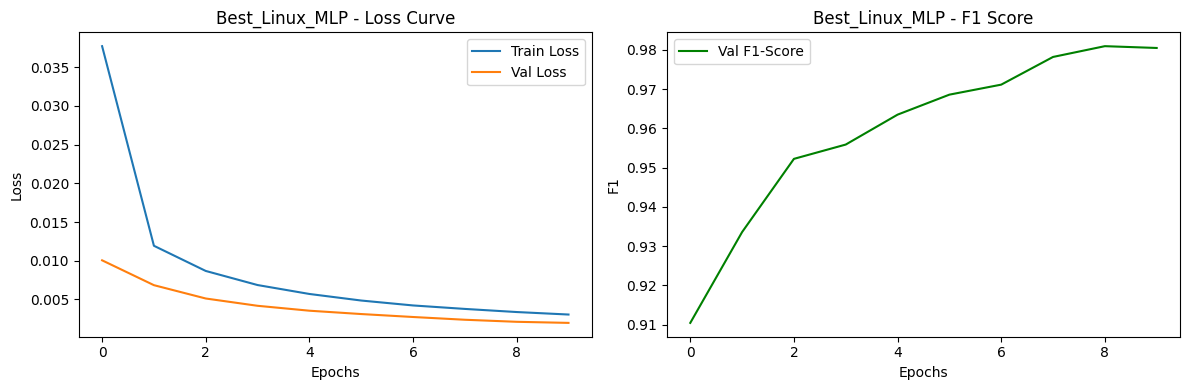

              precision    recall  f1-score   support

      Benign     0.9985    0.9920    0.9952    499992
   Malicious     0.9682    0.9940    0.9809    122473

    accuracy                         0.9924    622465
   macro avg     0.9834    0.9930    0.9881    622465
weighted avg     0.9926    0.9924    0.9924    622465



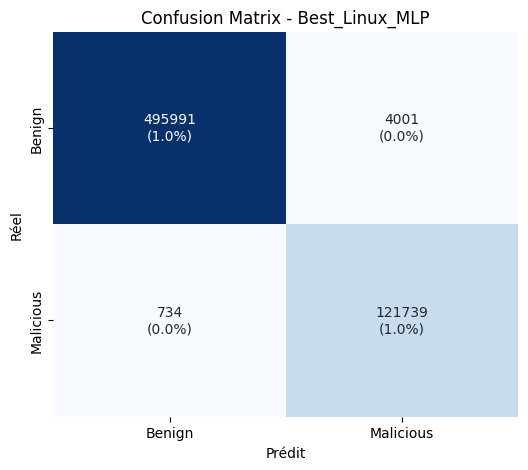

-> Résultat : F1=0.9809 | Recall=0.9940 | AUC=0.9995
------------------------------------------------------------

>>> Entraînement : Best_Linux_CNN (Features: 43)

[START] Entraînement : Best_Linux_CNN


Epoch 1/10 - Validation: 100%|██████████| 152/152 [00:05<00:00, 26.15it/s]


Epoch 1/10 | Train Loss: 0.0960 | Val Loss: 0.0139 | F1: 0.8600 | Precision: 0.7855 | Recall: 0.9500 | AUC: 0.9880


Epoch 2/10 - Validation: 100%|██████████| 152/152 [00:06<00:00, 25.16it/s]


Epoch 2/10 | Train Loss: 0.0218 | Val Loss: 0.0102 | F1: 0.8863 | Precision: 0.8205 | Recall: 0.9636 | AUC: 0.9928


Epoch 3/10 - Validation: 100%|██████████| 152/152 [00:05<00:00, 26.92it/s]


... (11 outputs left out)

Epoch 9/10 - Validation: 100%|██████████| 152/152 [00:05<00:00, 30.06it/s]


Epoch 9/10 | Train Loss: 0.0063 | Val Loss: 0.0044 | F1: 0.9448 | Precision: 0.9062 | Recall: 0.9868 | AUC: 0.9987


Epoch 10/10 - Validation: 100%|██████████| 152/152 [00:05<00:00, 26.61it/s]


Epoch 10/10 | Train Loss: 0.0057 | Val Loss: 0.0041 | F1: 0.9512 | Precision: 0.9150 | Recall: 0.9904 | AUC: 0.9988
[FIN] Durée: 342s | Best Val F1: 0.9512


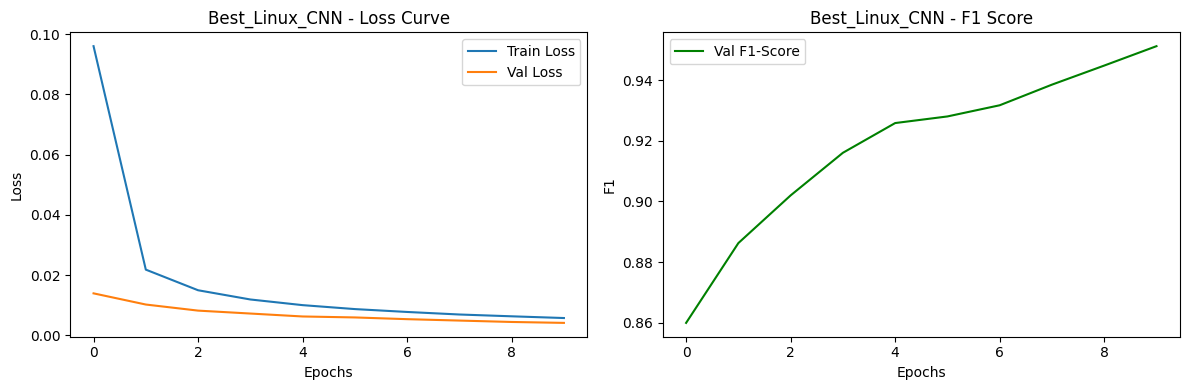

              precision    recall  f1-score   support

      Benign     0.9976    0.9775    0.9874    499992
   Malicious     0.9150    0.9904    0.9512    122473

    accuracy                         0.9800    622465
   macro avg     0.9563    0.9839    0.9693    622465
weighted avg     0.9814    0.9800    0.9803    622465



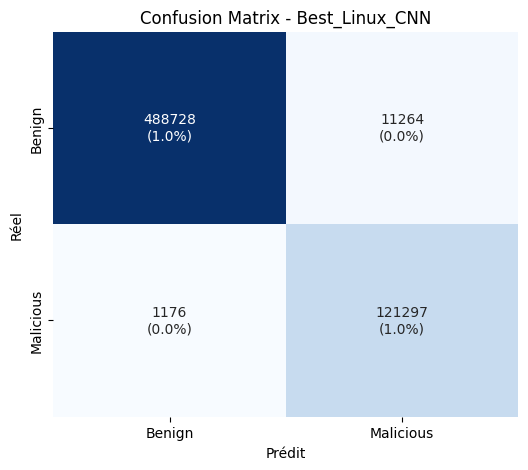

-> Résultat : F1=0.9512 | Recall=0.9904 | AUC=0.9988
------------------------------------------------------------

>>> Entraînement : Best_Linux_Attn (Features: 43)

[START] Entraînement : Best_Linux_Attn


Epoch 1/10 - Validation: 100%|██████████| 152/152 [00:06<00:00, 22.42it/s]


Epoch 1/10 | Train Loss: 0.0427 | Val Loss: 0.0139 | F1: 0.9316 | Precision: 0.8966 | Recall: 0.9695 | AUC: 0.9945


Epoch 2/10 - Validation: 100%|██████████| 152/152 [00:07<00:00, 21.65it/s]


Epoch 2/10 | Train Loss: 0.0079 | Val Loss: 0.0082 | F1: 0.9571 | Precision: 0.9381 | Recall: 0.9769 | AUC: 0.9975


Epoch 3/10 - Validation: 100%|██████████| 152/152 [00:06<00:00, 22.71it/s]


... (11 outputs left out)

Epoch 9/10 - Validation: 100%|██████████| 152/152 [00:06<00:00, 21.87it/s]


Epoch 9/10 | Train Loss: 0.0019 | Val Loss: 0.0014 | F1: 0.9878 | Precision: 0.9777 | Recall: 0.9982 | AUC: 0.9998


Epoch 10/10 - Validation: 100%|██████████| 152/152 [00:06<00:00, 22.09it/s]


Epoch 10/10 | Train Loss: 0.0019 | Val Loss: 0.0019 | F1: 0.9831 | Precision: 0.9696 | Recall: 0.9970 | AUC: 0.9997
[STOP] Early Stopping déclenché à l'époque 10
[FIN] Durée: 518s | Best Val F1: 0.9885


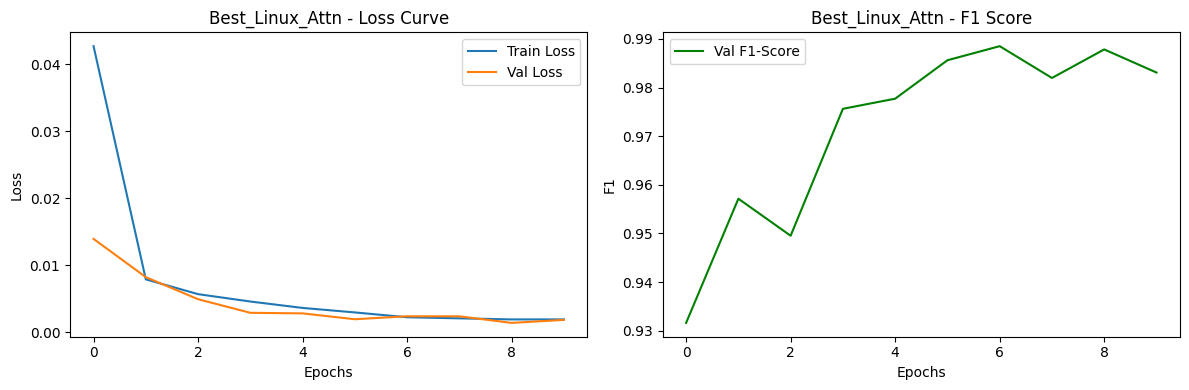

              precision    recall  f1-score   support

      Benign     0.9973    0.9970    0.9972    499992
   Malicious     0.9879    0.9891    0.9885    122473

    accuracy                         0.9955    622465
   macro avg     0.9926    0.9931    0.9928    622465
weighted avg     0.9955    0.9955    0.9955    622465



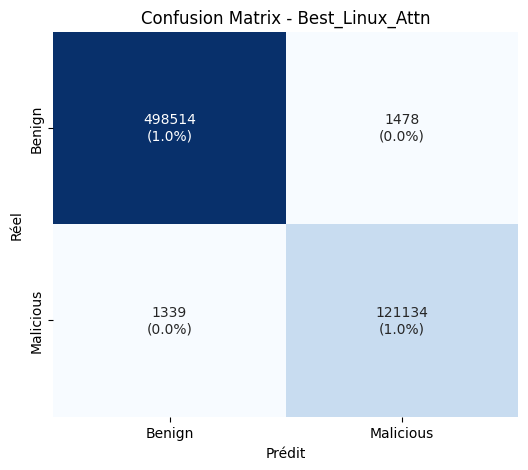

-> Résultat : F1=0.9885 | Recall=0.9891 | AUC=0.9997
------------------------------------------------------------

>>> Entraînement : Best_Pi_MLP (Features: 21)

[START] Entraînement : Best_Pi_MLP


Epoch 1/10 - Validation: 100%|██████████| 152/152 [00:05<00:00, 28.94it/s]


Epoch 1/10 | Train Loss: 0.0508 | Val Loss: 0.0128 | F1: 0.8194 | Precision: 0.7229 | Recall: 0.9455 | AUC: 0.9878


Epoch 2/10 - Validation: 100%|██████████| 152/152 [00:05<00:00, 28.41it/s]


Epoch 2/10 | Train Loss: 0.0170 | Val Loss: 0.0102 | F1: 0.9114 | Precision: 0.8825 | Recall: 0.9422 | AUC: 0.9912


Epoch 3/10 - Validation: 100%|██████████| 152/152 [00:05<00:00, 29.17it/s]


... (11 outputs left out)

Epoch 9/10 - Validation: 100%|██████████| 152/152 [00:04<00:00, 32.91it/s]


Epoch 9/10 | Train Loss: 0.0058 | Val Loss: 0.0038 | F1: 0.9576 | Precision: 0.9325 | Recall: 0.9841 | AUC: 0.9987


Epoch 10/10 - Validation: 100%|██████████| 152/152 [00:04<00:00, 32.98it/s]


Epoch 10/10 | Train Loss: 0.0052 | Val Loss: 0.0033 | F1: 0.9645 | Precision: 0.9466 | Recall: 0.9830 | AUC: 0.9990
[FIN] Durée: 297s | Best Val F1: 0.9645


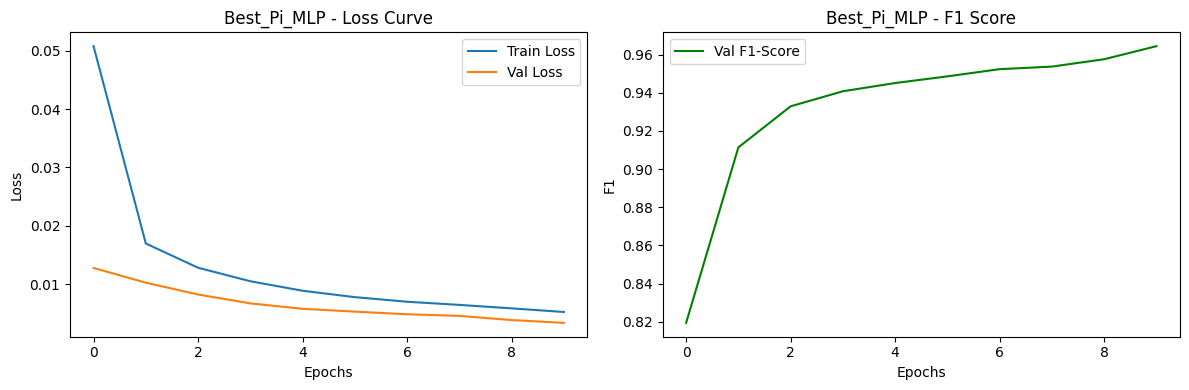

              precision    recall  f1-score   support

      Benign     0.9958    0.9864    0.9911    499992
   Malicious     0.9466    0.9830    0.9645    122473

    accuracy                         0.9858    622465
   macro avg     0.9712    0.9847    0.9778    622465
weighted avg     0.9861    0.9858    0.9859    622465



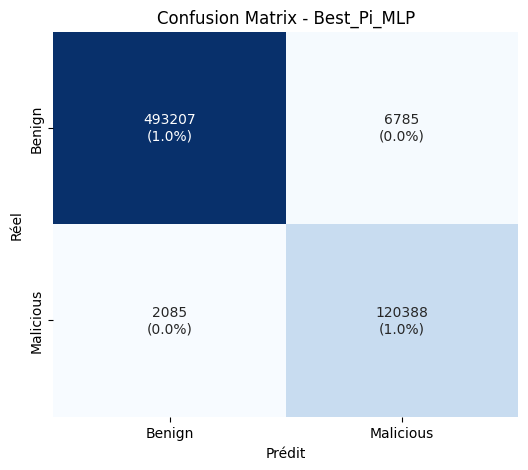

-> Résultat : F1=0.9645 | Recall=0.9830 | AUC=0.9990
------------------------------------------------------------

>>> Entraînement : Best_Pi_CNN (Features: 21)

[START] Entraînement : Best_Pi_CNN


Epoch 1/10 - Validation: 100%|██████████| 152/152 [00:04<00:00, 31.58it/s]


Epoch 1/10 | Train Loss: 0.1232 | Val Loss: 0.0178 | F1: 0.8571 | Precision: 0.7941 | Recall: 0.9309 | AUC: 0.9825


Epoch 2/10 - Validation: 100%|██████████| 152/152 [00:04<00:00, 33.03it/s]


Epoch 2/10 | Train Loss: 0.0287 | Val Loss: 0.0123 | F1: 0.8832 | Precision: 0.8265 | Recall: 0.9483 | AUC: 0.9880


Epoch 3/10 - Validation: 100%|██████████| 152/152 [00:04<00:00, 32.99it/s]


... (11 outputs left out)

Epoch 9/10 - Validation: 100%|██████████| 152/152 [00:04<00:00, 32.83it/s]


Epoch 9/10 | Train Loss: 0.0085 | Val Loss: 0.0057 | F1: 0.9358 | Precision: 0.8943 | Recall: 0.9814 | AUC: 0.9976


Epoch 10/10 - Validation: 100%|██████████| 152/152 [00:04<00:00, 32.09it/s]


Epoch 10/10 | Train Loss: 0.0080 | Val Loss: 0.0055 | F1: 0.9385 | Precision: 0.8964 | Recall: 0.9849 | AUC: 0.9978
[FIN] Durée: 260s | Best Val F1: 0.9385


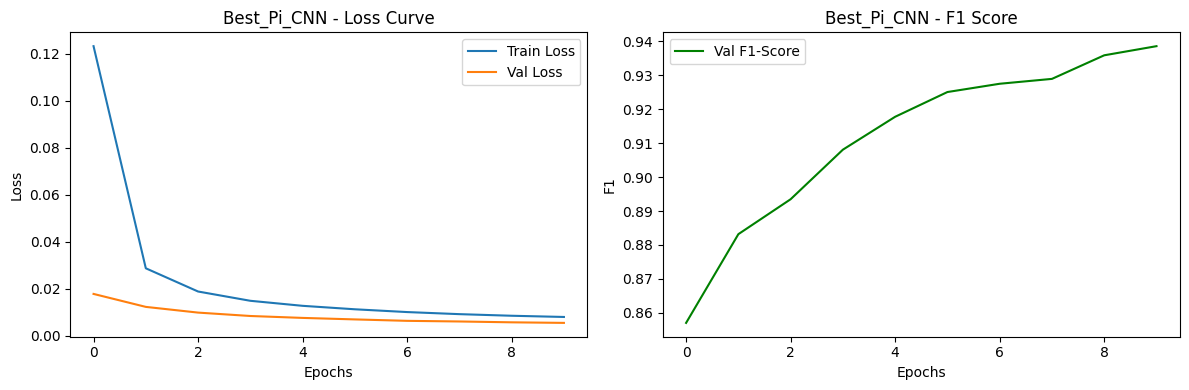

              precision    recall  f1-score   support

      Benign     0.9962    0.9721    0.9840    499992
   Malicious     0.8964    0.9849    0.9385    122473

    accuracy                         0.9746    622465
   macro avg     0.9463    0.9785    0.9613    622465
weighted avg     0.9766    0.9746    0.9751    622465



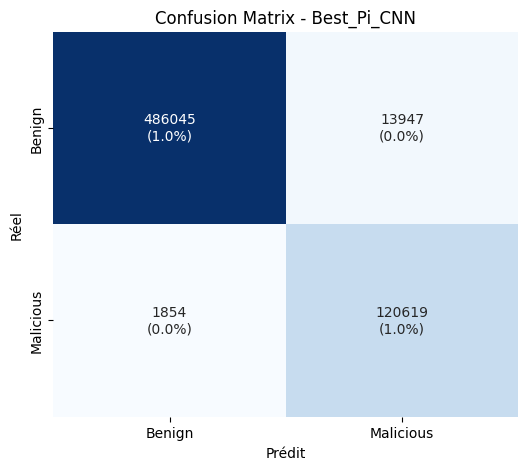

-> Résultat : F1=0.9385 | Recall=0.9849 | AUC=0.9978
------------------------------------------------------------

>>> Entraînement : Best_Pi_Attn (Features: 21)

[START] Entraînement : Best_Pi_Attn


Epoch 1/10 - Validation: 100%|██████████| 152/152 [00:05<00:00, 29.13it/s]


In [ ]:
results_log = []
confusion_matrices = {}

THRESHOLD = 0.5
EPOCHS = 10
PATIENCE = 3
# Configuration des expériences
# Format: (Platform, Architecture, Class, TrainL, TestL, PosWeight, InputDim)
experiments = [
    # --- LINUX (Serveur) ---
    ('Linux', 'MLP', MLP, train_loader_l, test_loader_l, pos_weight_l, len(data_linux['features']), 1.0),
    ('Linux', 'CNN', CNN_1D, train_loader_l, test_loader_l, pos_weight_l, len(data_linux['features']), 1.0),
    ('Linux', 'Attn', Self_Attention, train_loader_l, test_loader_l, pos_weight_l, len(data_linux['features']), 1.0),
    
    # --- RASPBERRY PI (Edge) ---
    ('Pi', 'MLP', MLP, train_loader_p, test_loader_p, pos_weight_p, len(data_pi['features']), 0.5),
    ('Pi', 'CNN', CNN_1D, train_loader_p, test_loader_p, pos_weight_p, len(data_pi['features']), 0.5),
    ('Pi', 'Attn', Self_Attention, train_loader_p, test_loader_p, pos_weight_p, len(data_pi['features']), 0.5),
]

print(f"🚀 DÉMARRAGE DU BENCHMARK COMPLET SUR {DEVICE}...")
print("="*80)

for platform, arch, model_cls, t_loader, v_loader, p_weight, in_dim, width_factor in experiments:
    model_name = f"Best_{platform}_{arch}"
    print(f"\n>>> Entraînement : {model_name} (Features: {in_dim})")
    
    model = model_cls(input_dim=in_dim, width_factor=width_factor)
    trained_model, history, train_time = train_model(
        model, t_loader, v_loader, p_weight, 
        epochs=EPOCHS, patience=PATIENCE, model_name=model_name, threshold=THRESHOLD
    )
    
    plt.figure(figsize=(12, 4))
    
    plt.subplot(1, 2, 1)
    plt.plot(history['train_loss'], label='Train Loss')
    plt.plot(history['val_loss'], label='Val Loss')
    plt.title(f'{model_name} - Loss Curve')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    
    plt.subplot(1, 2, 2)
    plt.plot(history['val_f1'], label='Val F1-Score', color='green')
    plt.title(f'{model_name} - F1 Score')
    plt.xlabel('Epochs')
    plt.ylabel('F1')
    plt.legend()
    
    plt.tight_layout()
    plt.show()
    
    trained_model.eval()
    
    sample_input, _ = next(iter(v_loader))
    sample_input = sample_input.to(DEVICE)
    tracemalloc.start()
    start_inf = time.time()
    with torch.no_grad():
        for _ in range(100):
            _ = trained_model(sample_input)
    end_inf = time.time()
    current_mem, peak_mem = tracemalloc.get_traced_memory()
    tracemalloc.stop()
    inference_time_us = ((end_inf - start_inf) / (100 * sample_input.size(0))) * 1_000_000
    memory_usage_mb = peak_mem / (1024 * 1024)
    
    model_path = f"models/{model_name}.pth"
    size_kb = os.path.getsize(model_path) / 1024
    
    y_true = []
    y_pred = []
    y_probs = []
    
    with torch.no_grad():
        for inputs, labels in v_loader:
            inputs = inputs.to(DEVICE)
            outputs = trained_model(inputs)
            probs = torch.sigmoid(outputs)
            preds = (probs > THRESHOLD).cpu().numpy()
            y_true.extend(labels.numpy())
            y_pred.extend(preds)
            y_probs.extend(probs.cpu().numpy())
            
    f1 = f1_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred)
    rec = recall_score(y_true, y_pred)
    acc = accuracy_score(y_true, y_pred)
    try:
        roc_auc = roc_auc_score(y_true, y_probs)
    except:
        roc_auc = 0.0
    fpr, tpr, _ = roc_curve(y_true, y_probs)
    
    print(classification_report(y_true, y_pred, target_names=['Benign', 'Malicious'], digits=4))
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(6, 5))
    cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
    labels = [f"{val}\n({pct:.1f}%)" for val, pct in zip(cm.flatten(), cm_norm.flatten())]
    labels = np.asarray(labels).reshape(2,2)
    sns.heatmap(cm, annot=labels, fmt='', cmap='Blues', cbar=False, 
            xticklabels=['Benign', 'Malicious'], yticklabels=['Benign', 'Malicious'])
    plt.title(f"Confusion Matrix - {model_name}")
    plt.ylabel('Réel')
    plt.xlabel('Prédit')
    plt.show()
    
    results_log.append({
        'Platform': platform,
        'Arch': arch,
        'Accuracy': f"{acc:.4f}",
        'F1-Score': f"{f1:.4f}",
        'Precision': f"{prec:.4f}",
        'Recall': f"{rec:.4f}",
        'ROC-AUC': f"{roc_auc:.4f}",
        'FPR': (cm[0,1] / (cm[0,1] + cm[0,0])) * 100,
        'Inference': round(inference_time_us, 2),
        'Size': round(size_kb, 1),
        "Memory Peak": round(memory_usage_mb, 2),
        'Train Time': round(train_time, 1)
    })
    confusion_matrices[f"{model_name}_{platform}"] = cm
    
    print(f"-> Résultat : F1={f1:.4f} | Recall={rec:.4f} | AUC={roc_auc:.4f}")
    print("-" * 60)

In [ ]:
print("\n=== 🏆 TABLEAU COMPARATIF FINAL ===")
df_results = pd.DataFrame(results_log)
df_results['F1-Score'] = df_results['F1-Score'].astype(float)
df_results['Accuracy'] = df_results['Accuracy'].astype(float)
df_results['Precision'] = df_results['Precision'].astype(float)
df_results['Recall'] = df_results['Recall'].astype(float)
df_results['ROC-AUC'] = df_results['ROC-AUC'].astype(float)
df_results['FPR'] = df_results['FPR'].astype(float)
df_results['Inference'] = df_results['Inference'].astype(float)
df_results['Size'] = df_results['Size'].astype(float)
df_results['Memory Peak'] = df_results['Memory Peak'].astype(float)
df_results['Train Time'] = df_results['Train Time'].astype(float)

display_cols = [
    'Arch', 'Platform', 'Accuracy', 'Precision', 'Recall', 
    'F1-Score', 'ROC-AUC', 'FPR', 
    'Inference', 'Size', 'Memory Peak', 'Train Time'
]

def highlight_best(s):
    is_max = s == s.max()
    is_min = s == s.min()
    if s.name in ['FPR', 'Inference', 'Size', 'Memory Peak', 'Train Time']:
        return ['background-color: #d4edda' if v else '' for v in is_min]
    else:
        return ['background-color: #d4edda' if v else '' for v in is_max]

styled_df = df_results[display_cols].style.apply(highlight_best, subset=display_cols[2:])\
             .format("{:.4f}", subset=['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC', 'FPR'])

display(styled_df)
df_results.to_csv("models/benchmark_results.csv", index=False)
df_melted = df_results.melt(id_vars=['Platform', 'Arch'], value_vars=['F1-Score', 'Recall'], var_name='Metric', value_name='Score')


df_metrics = df_results.melt(
    id_vars=['Arch', 'Platform'], 
    value_vars=['Accuracy', 'F1-Score', 'Precision', 'Recall', 'ROC-AUC', 'FPR'], 
    var_name='Metric', 
    value_name='Score'
)
sns.set_theme(style="whitegrid", font_scale=1.1)
g = sns.catplot(
    data=df_metrics, 
    kind="bar",
    x="Arch", 
    y="Score", 
    hue="Metric", 
    col="Platform",
    height=6, 
    aspect=1.2,
    palette="viridis",
    edgecolor="black",
    linewidth=1
)
g.figure.subplots_adjust(top=0.85)
g.figure.suptitle("Comparaison Détaillée", fontsize=16, fontweight='bold')
for ax in g.axes.flat:
    ax.set_ylim(0.0, 1.01) 
    for container in ax.containers:
        ax.bar_label(container, fmt='%.3f', padding=3, fontsize=9, rotation=90)
    ax.set_ylabel("Score (0.0 - 1.0)")
    ax.set_xlabel("Architecture")
    ax.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()
    
sns.set_theme(style="whitegrid", context="talk")
plt.figure(figsize=(12, 8))
scatter = sns.scatterplot(
    data=df_results, 
    x='FPR', 
    y='Recall', 
    hue='Arch', 
    style='Platform', 
    size='F1-Score',
    sizes=(200, 600),
    palette='viridis',
    edgecolor='black',
    alpha=0.8
)
for i in range(df_results.shape[0]):
    plt.text(
        x=df_results.FPR[i], 
        y=df_results.Recall[i] + 0.002,
        s=f"{df_results.Arch[i]}", 
        fontdict=dict(color='black', size=10, weight='bold'),
        ha='center'
    )
plt.axvline(x=1.0, color='red', linestyle='--', linewidth=2, label="Limite Max FPR (1%)")
plt.axhline(y=0.95, color='green', linestyle='--', linewidth=2, label="Objectif Recall (95%)")
plt.title("Analyse de Fiabilité IDS : Taux de Détection vs Fausses Alarmes", fontsize=16, weight='bold', pad=20)
plt.xlabel("Faux Positifs (FPR %) [Moins c'est mieux] ➔", fontsize=12)
plt.ylabel("Taux de Détection (Recall) [Plus c'est mieux] ➔", fontsize=12)
fpr_max = df_results['FPR'].max()
recall_min = df_results['Recall'].min()
plt.xlim(-0.1, max(1.5, fpr_max * 1.2)) 
plt.ylim(max(0.8, recall_min - 0.05), 1.005)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', borderaxespad=0.)
plt.text(0, 1.002, "⭐ ZONE IDÉALE", color='green', weight='bold', ha='left', va='bottom')
plt.tight_layout()
plt.show()

print("✅ Benchmarks terminés. Résultats sauvegardés dans 'models/benchmark_results.csv'.")


In [ ]:
import pandas as pd
import torch
import joblib
import numpy as np
import time
import os

# ==============================================================================
# 1. SÉLECTION AUTOMATIQUE DU MEILLEUR MODÈLE (Depuis le CSV)
# ==============================================================================
print("🔍 Analyse du benchmark pour trouver le champion...")

try:
    # Chargement du fichier de résultats
    df_results = pd.read_csv("models/benchmark_results.csv")
    
    # Nettoyage et conversion (au cas où ce soit des strings)
    df_results['F1-Score'] = df_results['F1-Score'].astype(float)
    df_results['Accuracy'] = df_results['Accuracy'].astype(float)
    df_results['Precision'] = df_results['Precision'].astype(float)
    df_results['Recall'] = df_results['Recall'].astype(float)
    df_results['ROC-AUC'] = df_results['ROC-AUC'].astype(float)
    df_results['FPR'] = df_results['FPR'].astype(float)
    
    # Filtrage pour la plateforme Linux uniquement
    linux_results = df_results[df_results['Platform'] == 'Linux']
    
    if linux_results.empty:
        raise ValueError("Aucun résultat pour 'Linux' trouvé dans le CSV.")

    # Tri par F1-Score décroissant -> Le premier est le meilleur
    best_row = linux_results.sort_values(by='F1-Score', ascending=False).iloc[0]
    
    BEST_ARCH = best_row['Arch']
    # On reconstruit le nom du fichier modèle sauvegardé
    BEST_MODEL_PATH = f"models/Best_Linux_{BEST_ARCH}.pth"
    
    print(f"🏆 CHAMPION DÉTECTÉ : Architecture {BEST_ARCH}")
    print(f"   📊 F1-Score : {best_row['F1-Score']:.4f}")
    print(f"   📂 Fichier  : {BEST_MODEL_PATH}")

except FileNotFoundError:
    raise FileNotFoundError("Le fichier 'benchmark_results.csv' n'existe pas. Lance l'entraînement d'abord.")

# ==============================================================================
# 2. CHARGEMENT DES RESSOURCES (Scaler & Modèle)
# ==============================================================================
print("\n🛠️ Chargement des ressources système...")
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# A. Charger le Scaler et la liste des Features
try:
    scaler = joblib.load('datasets/scaler_linux.pkl')
    features_list = joblib.load('datasets/features_linux_list.pkl')
    INPUT_DIM = len(features_list)
    print(f"   ✅ Scaler chargé. (Attend {INPUT_DIM} features)")
except FileNotFoundError:
    raise FileNotFoundError("Les fichiers .pkl dans datasets/ sont manquants.")

# B. Instancier la bonne architecture
# (Assure-toi que les classes MLP, CNN_1D, Self_Attention sont définies dans le notebook)
if BEST_ARCH == 'MLP':
    model = MLP(input_dim=INPUT_DIM, width_factor=1.0)
elif BEST_ARCH == 'CNN':
    model = CNN_1D(input_dim=INPUT_DIM, width_factor=1.0)
elif BEST_ARCH == 'Attn':
    model = Self_Attention(input_dim=INPUT_DIM, width_factor=1.0)
else:
    raise ValueError(f"Architecture inconnue dans le CSV : {BEST_ARCH}")

# C. Charger les poids
if not os.path.exists(BEST_MODEL_PATH):
    raise FileNotFoundError(f"Le fichier de poids {BEST_MODEL_PATH} est introuvable !")

model.load_state_dict(torch.load(BEST_MODEL_PATH, map_location=DEVICE))
model.to(DEVICE)
model.eval()
print(f"   ✅ Modèle {BEST_ARCH} chargé et prêt sur {DEVICE}.")

# ==============================================================================
# 3. MOTEUR D'INFÉRENCE TEMPS RÉEL (Simulation)
# ==============================================================================
def preprocess_packet(row_dict, expected_features, scaler):
    """
    Transforme une ligne brute (dict) en tenseur PyTorch prêt pour le modèle.
    Gère l'alignement des colonnes et le scaling.
    """
    # 1. Convertir en DataFrame
    df = pd.DataFrame([row_dict])
    
    # 2. Clipping (Gestion des infinis)
    # On remplace les infinis par une grande valeur arbitraire (ex: 1 milliard)
    df.replace([np.inf, -np.inf], 1e9, inplace=True)
    df.fillna(0, inplace=True)
    
    # 3. Alignement des colonnes (Critique !)
    # Créer un DF vide avec exactement les colonnes attendues par le modèle
    df_aligned = pd.DataFrame(columns=expected_features)
    
    # Remplir avec les données qu'on a, ignorer le reste
    common_cols = list(set(df.columns) & set(expected_features))
    df_aligned.loc[0, common_cols] = df.loc[0, common_cols] # type: ignore
    
    # Remplir les trous (features manquantes) par 0
    df_aligned.fillna(0, inplace=True)
    
    # S'assurer de l'ordre strict
    df_final = df_aligned[expected_features]
    
    # 4. Scaling
    X_scaled = scaler.transform(df_final)
    
    return torch.tensor(X_scaled, dtype=torch.float32).to(DEVICE)

# ==============================================================================
# 4. LANCEMENT DE LA SIMULATION SUR 'capture_linux.csv'
# ==============================================================================
CAPTURE_FILE = "capture_linux.csv"
print(f"\n📡 Démarrage de la surveillance sur : {CAPTURE_FILE}")
print("="*70)

if not os.path.exists(CAPTURE_FILE):
    print(f"❌ ERREUR : Le fichier {CAPTURE_FILE} n'existe pas.")
    print("👉 Lance d'abord le script Scapy (Cellule précédente) pour générer du trafic.")
else:
    # Lecture du fichier de capture
    traffic_df = pd.read_csv(CAPTURE_FILE)
    
    alerts = 0
    start_time = time.time()
    
    print(f"Flux à analyser : {len(traffic_df)}")
    print("-" * 70)
    print(f"{'TIMESTAMP':<10} | {'PROBABILITÉ':<12} | {'STATUS':<10} | {'DÉTAILS'}")
    print("-" * 70)

    for idx, row in traffic_df.iterrows():
        # Simulation d'arrivée en temps réel (optionnel, pour l'effet)
        # time.sleep(0.02) 
        
        # Prétraitement
        input_tensor = preprocess_packet(row, features_list, scaler)
        
        # Prédiction
        with torch.no_grad():
            output = model(input_tensor)
            prob = torch.sigmoid(output).item()
        
        # Logique d'alerte
        timestamp = time.strftime("%H:%M:%S")
        
        if prob > 0.5: # SEUIL D'ALERTE
            alerts += 1
            print(f"🚨 {timestamp} | {prob:.4f}       | MALICIOUS  | IP Src: {row.get('Source IP', '?')} -> Port: {row.get('Destination Port', '?')}")
        else:
            # On n'affiche pas tout pour ne pas spammer, juste un indicateur visuel
            # ou on affiche les flux bénins avec une faible probabilité
            if idx % 10 == 0: # type: ignore # Affiche 1 flux bénin sur 10 pour montrer que ça vit
                print(f"   {timestamp} | {prob:.4f}       | Benign     | Flux normal...")

    duration = time.time() - start_time
    print("="*70)
    print(f"✅ Analyse terminée en {duration:.2f} secondes.")
    print(f"📊 Bilan : {len(traffic_df)} flux analysés, {alerts} ALERTES générées.")